<a href="https://colab.research.google.com/github/Gerry004p/Cyber-Shujaa/blob/main/Final_Exam.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
Name: Gerald Mawili Musyoki
ID  : CS-DA02-25026
Title: Final Exam Notebook
'''

'\nName: Gerald Mawili Musyoki\nID  : CS-DA02-25026\nTitle: Final Exam Notebook\n'

In [ ]:
from google.colab import files
import pandas as pd
import io
uploaded = files.upload()

Saving Diabetes_Dataset.zip to Diabetes_Dataset.zip


In [ ]:
import zipfile
import io
import pandas as pd
import os

# Assume 'uploaded' is available from the previous cell's execution.
# It contains {'Diabetes_Dataset.zip': b'...'}.

if 'Diabetes_Dataset.zip' in uploaded:
    zip_file_bytes = uploaded['Diabetes_Dataset.zip']
    zip_file_object = io.BytesIO(zip_file_bytes)

    # Create a temporary directory to extract contents
    extract_path = '/tmp/diabetes_dataset_extracted'
    os.makedirs(extract_path, exist_ok=True)

    with zipfile.ZipFile(zip_file_object, 'r') as z:
        z.extractall(extract_path)

    # Find the CSV file within the extracted contents
    csv_file_path = None
    for root, dirs, files in os.walk(extract_path):
        for file in files:
            if file.lower().endswith('.csv'):
                csv_file_path = os.path.join(root, file)
                break
        if csv_file_path:
            break

    if csv_file_path:
        df = pd.read_csv(csv_file_path)
        print("DataFrame 'df' loaded successfully from:", csv_file_path)
        print("\nHead of the DataFrame:")
        print(df.head(10))
        print("\nTail of the DataFrame:")
        print(df.tail(10))
    else:
        print("Error: No CSV file found in the 'Diabetes_Dataset.zip' archive.")
else:
    print("Error: 'Diabetes_Dataset.zip' not found in the uploaded files.")


DataFrame 'df' loaded successfully from: /tmp/diabetes_dataset_extracted/Diabetes_Dataset/diabetic_data.csv

Head of the DataFrame:
   encounter_id  patient_nbr             race  gender       age weight  \
0       2278392      8222157        Caucasian  Female    [0-10)      ?   
1        149190     55629189        Caucasian  Female   [10-20)      ?   
2         64410     86047875  AfricanAmerican  Female   [20-30)      ?   
3        500364     82442376        Caucasian    Male   [30-40)      ?   
4         16680     42519267        Caucasian    Male   [40-50)      ?   
5         35754     82637451        Caucasian    Male   [50-60)      ?   
6         55842     84259809        Caucasian    Male   [60-70)      ?   
7         63768    114882984        Caucasian    Male   [70-80)      ?   
8         12522     48330783        Caucasian  Female   [80-90)      ?   
9         15738     63555939        Caucasian  Female  [90-100)      ?   

   admission_type_id  discharge_disposition_id  admis

In [ ]:
num_rows = df.shape[0]
num_columns = df.shape[1]
print(f"The dataset has {num_rows} rows and {num_columns} columns.")

The dataset has 101766 rows and 50 columns.


In [ ]:
#listed all columns and data types
print(f"\nNumber of integer columnns is {df.select_dtypes(include=['int64']).shape[1]}")
print(f"\nNumber of categorical columnns is {df.select_dtypes(include=['object']).shape[1]}")



Number of integer columnns is 13

Number of categorical columnns is 37


In [ ]:
#generated descriptive statistics for key numerical columns
numerical_stats=df.describe()
print(numerical_stats)
#Brief analysis example
print(f"time in hospital")
print(f"number of procedures")

       encounter_id   patient_nbr  admission_type_id  \
count  1.017660e+05  1.017660e+05      101766.000000   
mean   1.652016e+08  5.433040e+07           2.024006   
std    1.026403e+08  3.869636e+07           1.445403   
min    1.252200e+04  1.350000e+02           1.000000   
25%    8.496119e+07  2.341322e+07           1.000000   
50%    1.523890e+08  4.550514e+07           1.000000   
75%    2.302709e+08  8.754595e+07           3.000000   
max    4.438672e+08  1.895026e+08           8.000000   

       discharge_disposition_id  admission_source_id  time_in_hospital  \
count             101766.000000        101766.000000     101766.000000   
mean                   3.715642             5.754437          4.395987   
std                    5.280166             4.064081          2.985108   
min                    1.000000             1.000000          1.000000   
25%                    1.000000             1.000000          2.000000   
50%                    1.000000             7.00000

In [ ]:
#displayed unique vary counts for selected categorical columns
#race
race_counts = df['race'].value_counts()
print(race_counts)
#gender
gender_counts = df['gender'].value_counts()
print(gender_counts)

race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


In [ ]:
#missing value analysis and dropping
missing_values = df.isnull().sum()
print(missing_values)

encounter_id                    0
patient_nbr                     0
race                            0
gender                          0
age                             0
weight                          0
admission_type_id               0
discharge_disposition_id        0
admission_source_id             0
time_in_hospital                0
payer_code                      0
medical_specialty               0
num_lab_procedures              0
num_procedures                  0
num_medications                 0
number_outpatient               0
number_emergency                0
number_inpatient                0
diag_1                          0
diag_2                          0
diag_3                          0
number_diagnoses                0
max_glu_serum               96420
A1Cresult                   84748
metformin                       0
repaglinide                     0
nateglinide                     0
chlorpropamide                  0
glimepiride                     0
acetohexamide 

In [ ]:
#imputing race
df['race'].fillna(df['race'].mode()[0], inplace=True)

/tmp/ipython-input-2701392170.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['race'].fillna(df['race'].mode()[0], inplace=True)


In [ ]:
#replacing missing values
df['gender'].fillna('Unknown', inplace=True)

/tmp/ipython-input-3539564229.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['gender'].fillna('Unknown', inplace=True)


Column: encounter_id
Q1 (25th percentile): 84961194.0
Q3 (75th percentile): 230270887.5
IQR (Interquartile Range): 145309693.5
Upper Bound for outliers: 448235427.75
Lower Bound for outliers: -133003346.25
Number of outliers: 0


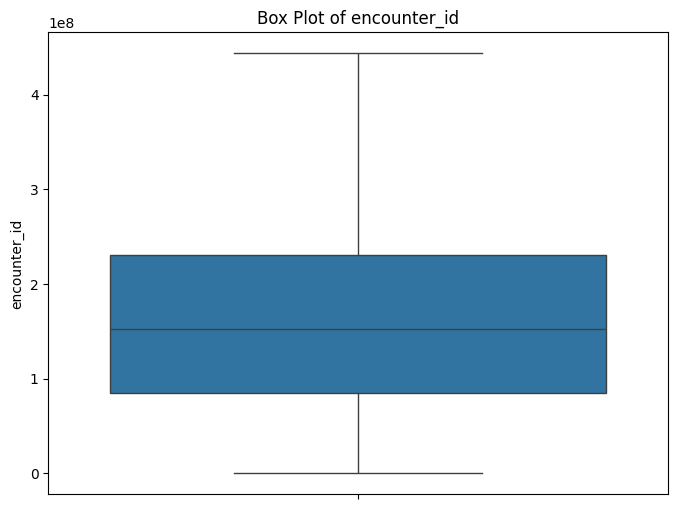

Column: patient_nbr
Q1 (25th percentile): 23413221.0
Q3 (75th percentile): 87545949.75
IQR (Interquartile Range): 64132728.75
Upper Bound for outliers: 183745042.875
Lower Bound for outliers: -72785872.125
Number of outliers: 247


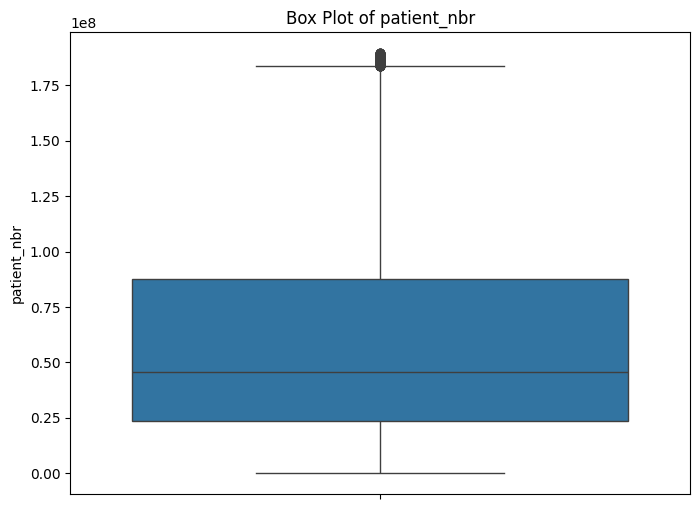

Column: admission_type_id
Q1 (25th percentile): 1.0
Q3 (75th percentile): 3.0
IQR (Interquartile Range): 2.0
Upper Bound for outliers: 6.0
Lower Bound for outliers: -2.0
Number of outliers: 341


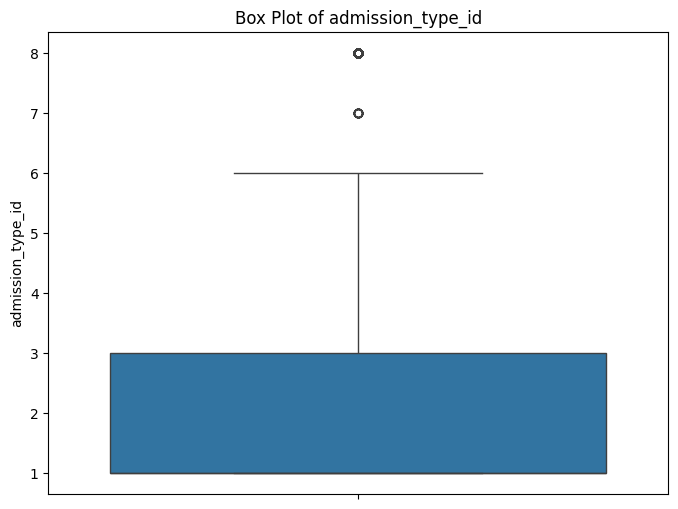

Column: discharge_disposition_id
Q1 (25th percentile): 1.0
Q3 (75th percentile): 4.0
IQR (Interquartile Range): 3.0
Upper Bound for outliers: 8.5
Lower Bound for outliers: -3.5
Number of outliers: 9818


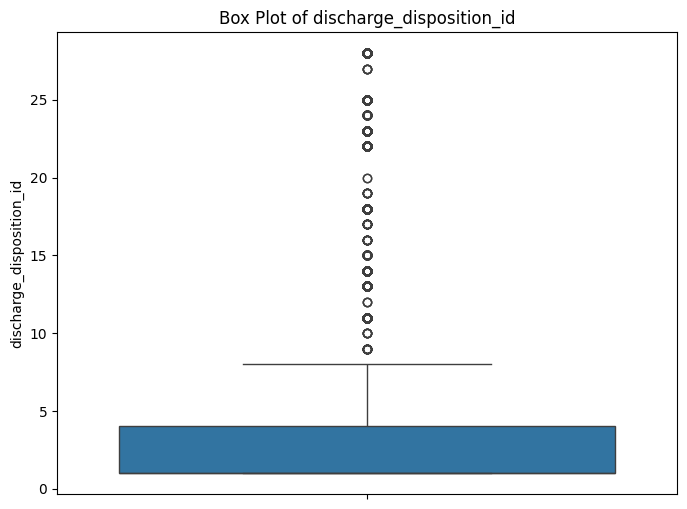

Column: admission_source_id
Q1 (25th percentile): 1.0
Q3 (75th percentile): 7.0
IQR (Interquartile Range): 6.0
Upper Bound for outliers: 16.0
Lower Bound for outliers: -8.0
Number of outliers: 6956


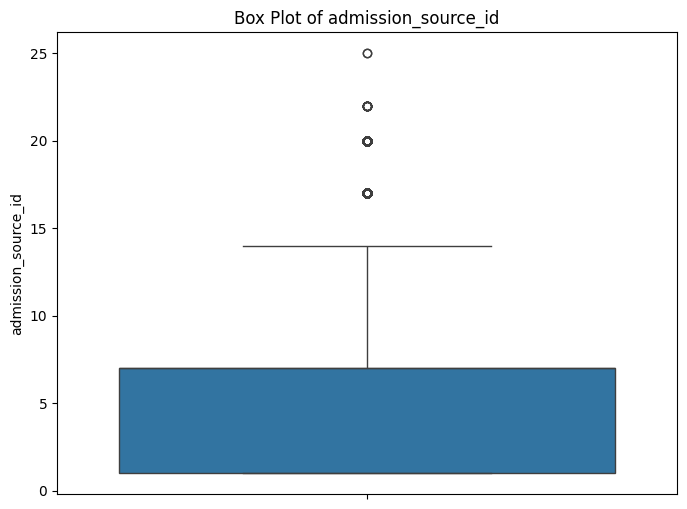

Column: time_in_hospital
Q1 (25th percentile): 2.0
Q3 (75th percentile): 6.0
IQR (Interquartile Range): 4.0
Upper Bound for outliers: 12.0
Lower Bound for outliers: -4.0
Number of outliers: 2252


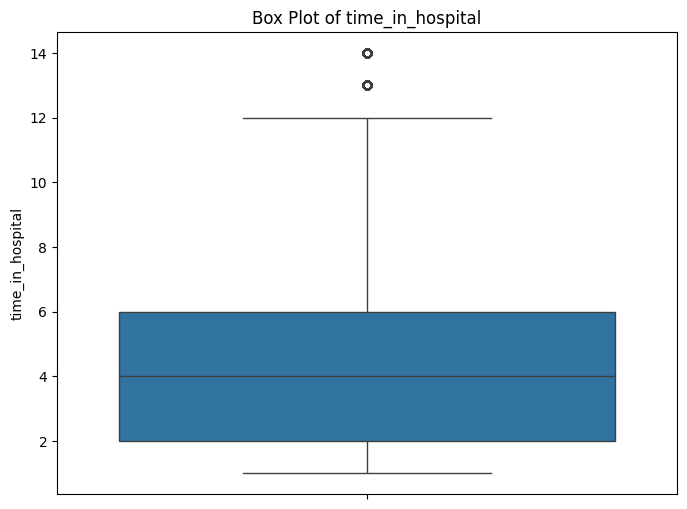

Column: num_lab_procedures
Q1 (25th percentile): 31.0
Q3 (75th percentile): 57.0
IQR (Interquartile Range): 26.0
Upper Bound for outliers: 96.0
Lower Bound for outliers: -8.0
Number of outliers: 143


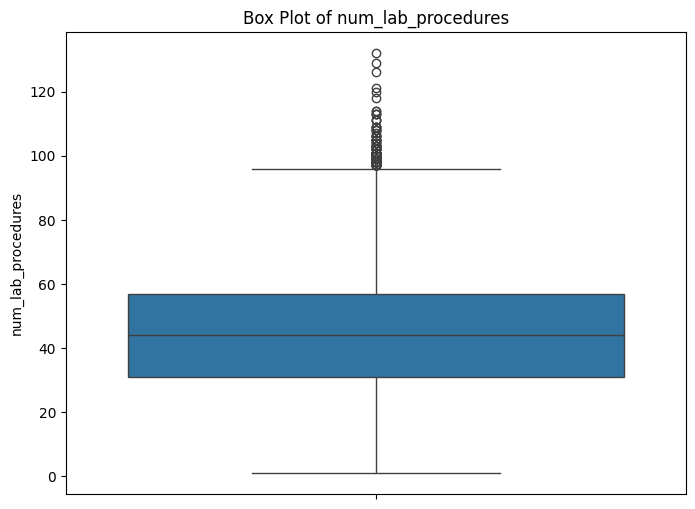

Column: num_procedures
Q1 (25th percentile): 0.0
Q3 (75th percentile): 2.0
IQR (Interquartile Range): 2.0
Upper Bound for outliers: 5.0
Lower Bound for outliers: -3.0
Number of outliers: 4954


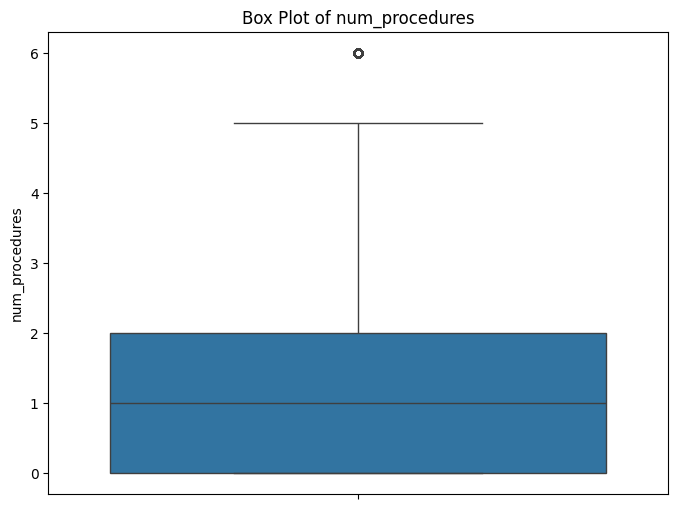

Column: num_medications
Q1 (25th percentile): 10.0
Q3 (75th percentile): 20.0
IQR (Interquartile Range): 10.0
Upper Bound for outliers: 35.0
Lower Bound for outliers: -5.0
Number of outliers: 2557


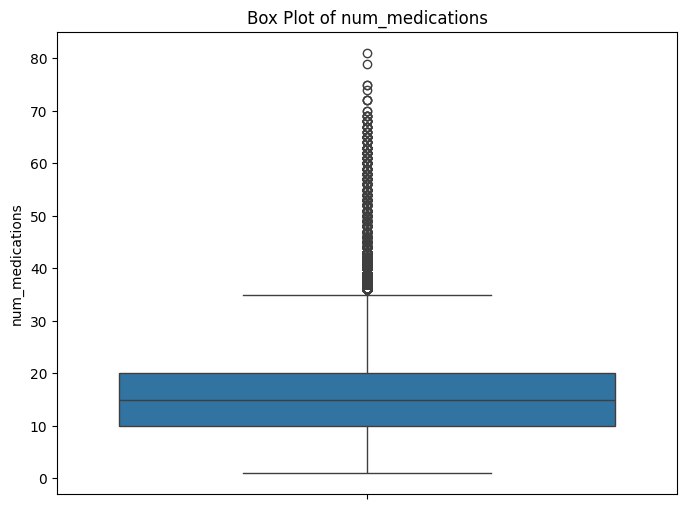

Column: number_outpatient
Q1 (25th percentile): 0.0
Q3 (75th percentile): 0.0
IQR (Interquartile Range): 0.0
Upper Bound for outliers: 0.0
Lower Bound for outliers: 0.0
Number of outliers: 16739


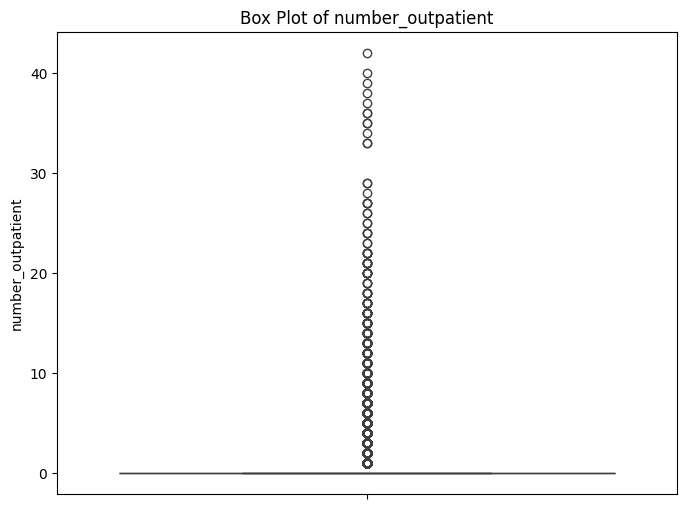

Column: number_emergency
Q1 (25th percentile): 0.0
Q3 (75th percentile): 0.0
IQR (Interquartile Range): 0.0
Upper Bound for outliers: 0.0
Lower Bound for outliers: 0.0
Number of outliers: 11383


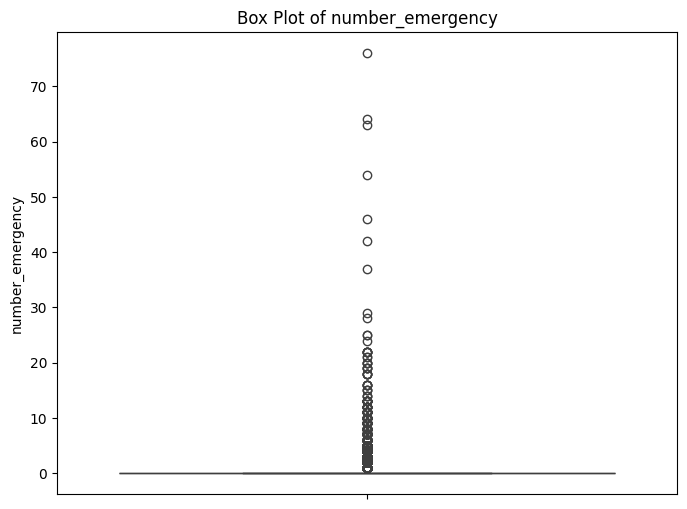

Column: number_inpatient
Q1 (25th percentile): 0.0
Q3 (75th percentile): 1.0
IQR (Interquartile Range): 1.0
Upper Bound for outliers: 2.5
Lower Bound for outliers: -1.5
Number of outliers: 7049


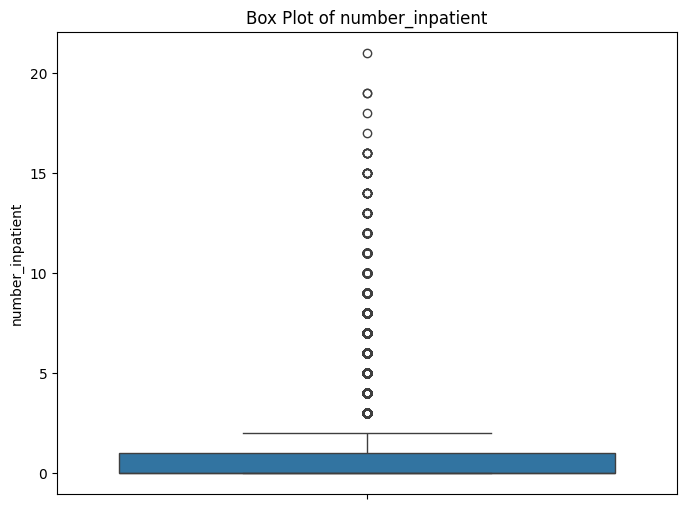

Column: number_diagnoses
Q1 (25th percentile): 6.0
Q3 (75th percentile): 9.0
IQR (Interquartile Range): 3.0
Upper Bound for outliers: 13.5
Lower Bound for outliers: 1.5
Number of outliers: 281


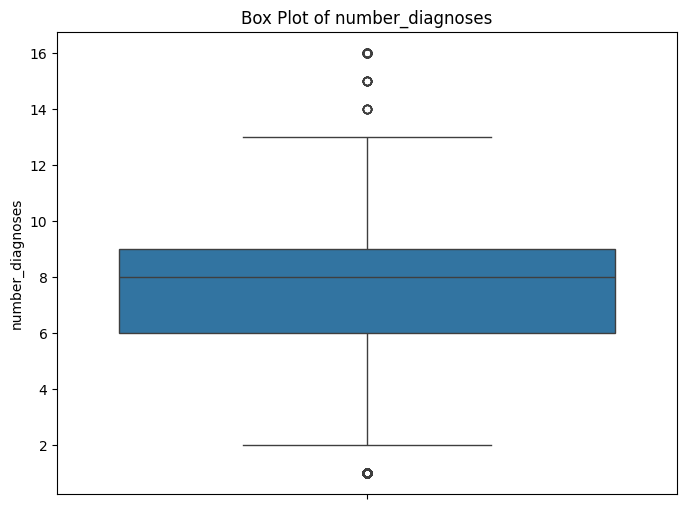

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# detecting outliers
numerical_columns = df.select_dtypes(include=['int64', 'float64'])
for column in numerical_columns.columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR

    print(f"Column: {column}")
    print(f"Q1 (25th percentile): {Q1}")
    print(f"Q3 (75th percentile): {Q3}")
    print(f"IQR (Interquartile Range): {IQR}")
    print(f"Upper Bound for outliers: {upper_bound}")
    print(f"Lower Bound for outliers: {lower_bound}")

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    print(f"Number of outliers: {len(outliers)}")

    # creating visualization
    plt.figure(figsize=(8, 6))
    sns.boxplot(y=df[column])
    plt.title(f'Box Plot of {column}')
    plt.ylabel(column)
    plt.show()


In [ ]:
#converting age ranges
age_mapping = {
    '[0-10)': 5,
    '[10-20)': 15,
    '[20-30)': 25,
    '[30-40)': 35,
    '[40-50)': 45,
    '[50-60)': 55,
    '[60-70)': 65,
    '[70-80)': 75,
    '[80-90)': 85,
    '[90-100)': 95
}

In [ ]:
#before and after comparison
print(df['age'].value_counts())

age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64


In [ ]:
#patient risk score
df["patient_risk_score"] = df["num_medications"] * df["number_outpatient"]
conditions=[(df['patient_risk_score']>=12,(df['patient_risk_score']>=6,'low risk'))]

In [ ]:
#total visits
df['total_visits'] = df['number_emergency'] + df['number_inpatient'] + df['number_outpatient']

In [ ]:
#created medication intensity
df['medication_intensity'] = df['num_medications'] / df['total_visits']


--- Univariate Analysis for time_in_hospital ---
count    101766.000000
mean          4.395987
std           2.985108
min           1.000000
25%           2.000000
50%           4.000000
75%           6.000000
max          14.000000
Name: time_in_hospital, dtype: float64


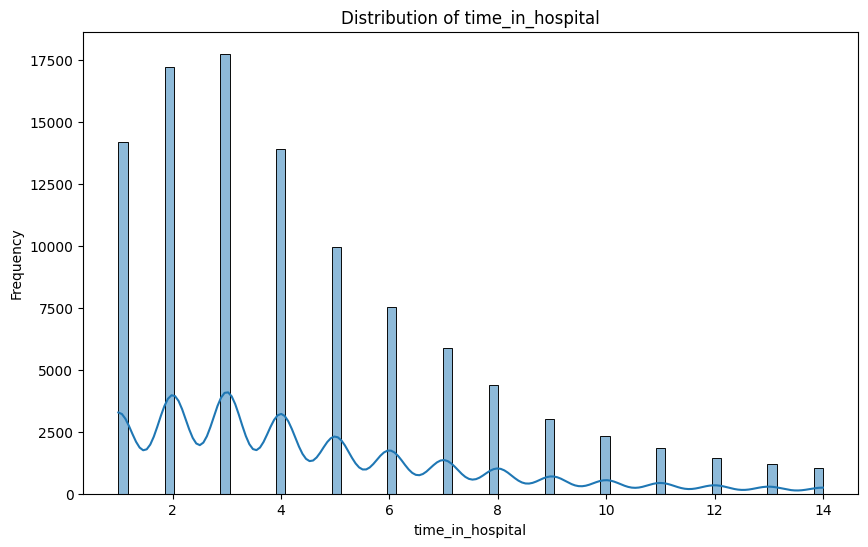


--- Univariate Analysis for num_lab_procedures ---
count    101766.000000
mean         43.095641
std          19.674362
min           1.000000
25%          31.000000
50%          44.000000
75%          57.000000
max         132.000000
Name: num_lab_procedures, dtype: float64


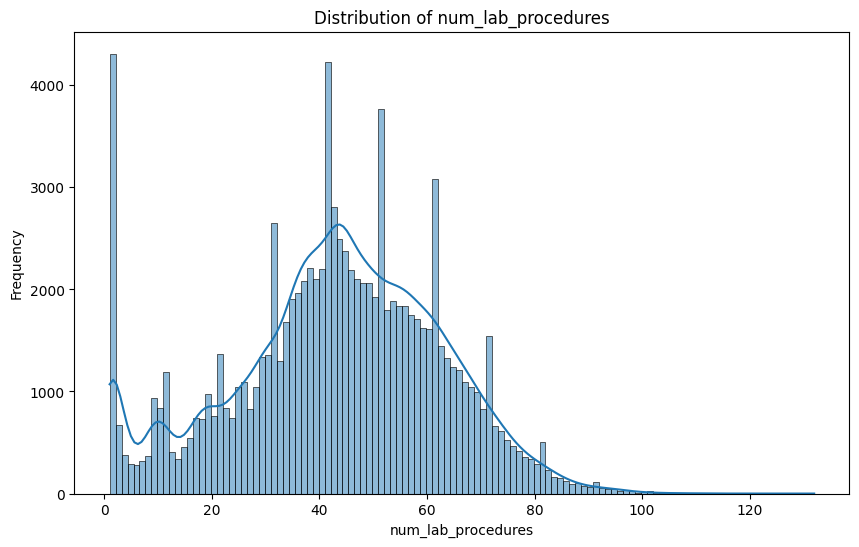


--- Univariate Analysis for num_medications ---
count    101766.000000
mean         16.021844
std           8.127566
min           1.000000
25%          10.000000
50%          15.000000
75%          20.000000
max          81.000000
Name: num_medications, dtype: float64


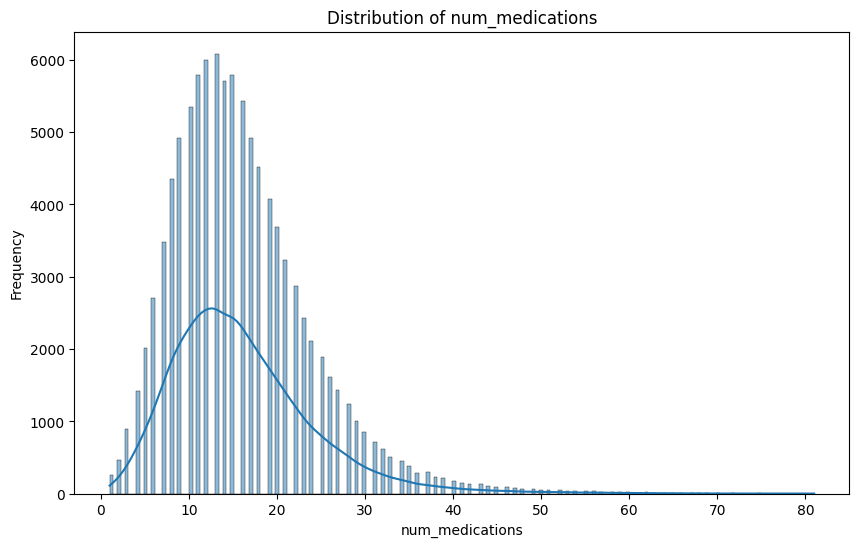


--- Univariate Analysis for age_midpoint ---
count    101766.000000
mean         65.967022
std          15.940838
min           5.000000
25%          55.000000
50%          65.000000
75%          75.000000
max          95.000000
Name: age_midpoint, dtype: float64


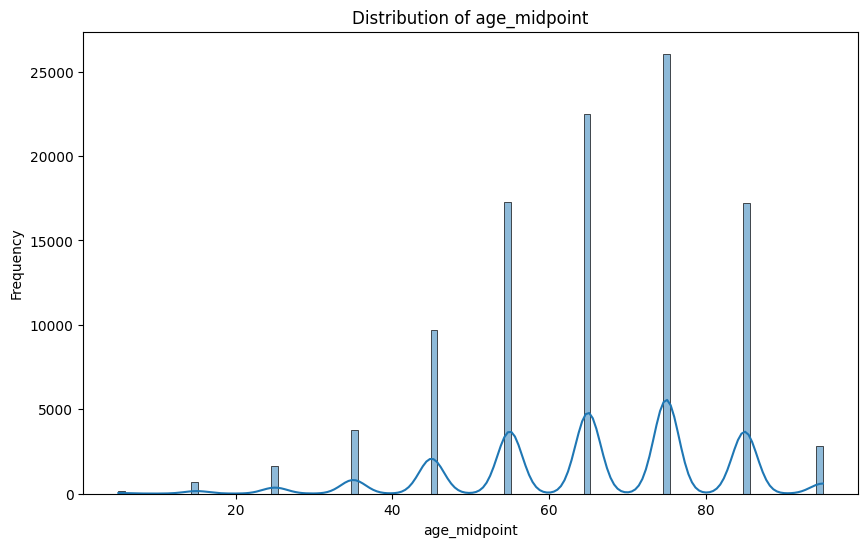

In [ ]:
#univariate analysis of the dataset
import matplotlib.pyplot as plt
import seaborn as sns

# Convert age ranges to numerical midpoints first
df['age_midpoint'] = df['age'].map(age_mapping)

analysis_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_medications',
    'age_midpoint'
]

for feature in analysis_features:
    print(f"\n--- Univariate Analysis for {feature} ---")
    print(df[feature].describe())

    plt.figure(figsize=(10, 6))
    sns.histplot(df[feature], kde=True)
    plt.title(f'Distribution of {feature}')
    plt.xlabel(feature)
    plt.ylabel('Frequency')
    plt.show()


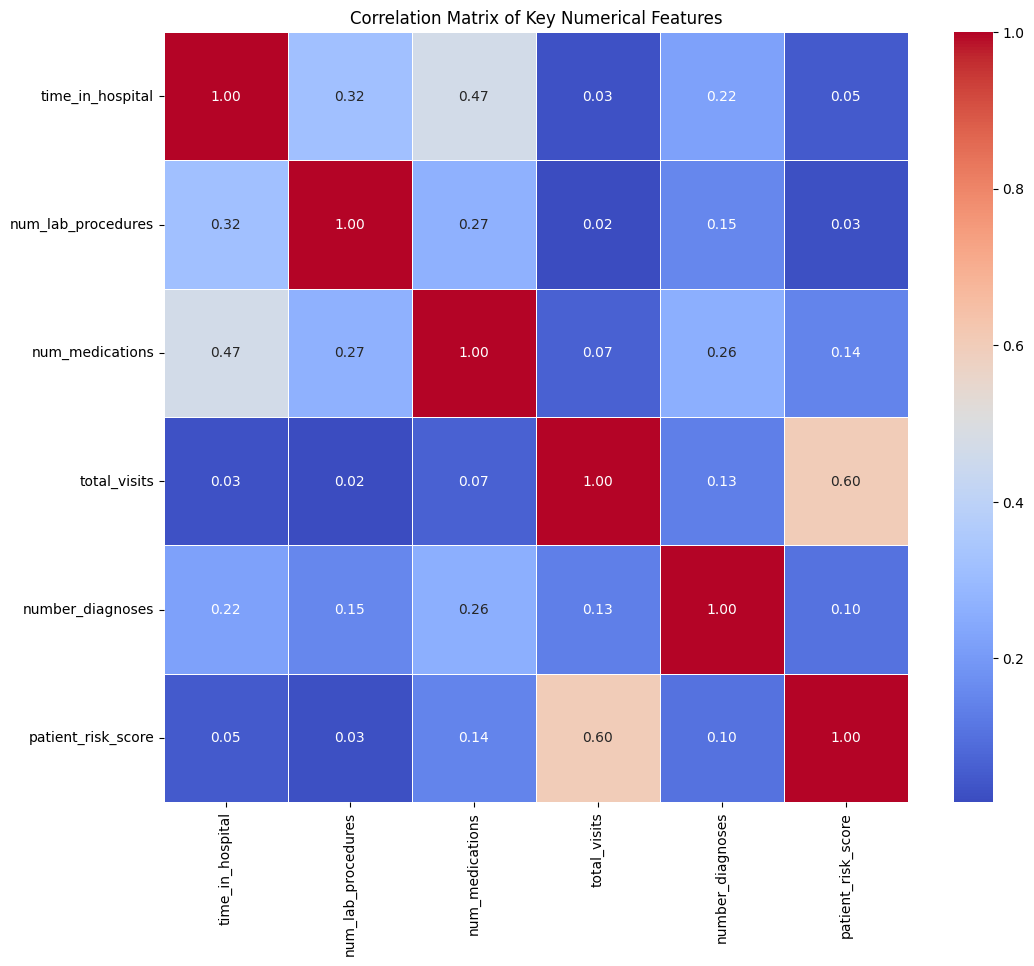

In [ ]:
#bivariate and multivariate analysis
import seaborn as sns
import matplotlib.pyplot as plt

# Task,Steps (Python/Pandas/Seaborn),Insights
# Heatmap,"1. Select key numerical features (e.g., time_in_hospital, num_lab_procedures, num_medications, TotalVisits, number_diagnoses). 2. Calculate the correlation matrix: df[features].corr(). 3. Plot with seaborn.heatmap().",Insights: Look for strong correlations (>= 0.7 or <= -0.7) between variables. This can highlight dependencies or multicollinearity.

# Select key numerical features for correlation analysis
# Assuming 'total_visits' is created in a previous step
numerical_features = [
    'time_in_hospital',
    'num_lab_procedures',
    'num_medications',
    'total_visits', # Assuming this is created previously
    'number_diagnoses',
    'patient_risk_score' # Assuming this is created previously
]

# Ensure all features exist before proceeding
existing_numerical_features = [f for f in numerical_features if f in df.columns]

if len(existing_numerical_features) < len(numerical_features):
    print("Warning: Some specified numerical features do not exist in the DataFrame.")
    print(f"Available features for correlation: {existing_numerical_features}")

if existing_numerical_features:
    # Calculate the correlation matrix
    correlation_matrix = df[existing_numerical_features].corr()

    # Plot the heatmap
    plt.figure(figsize=(12, 10))
    sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
    plt.title('Correlation Matrix of Key Numerical Features')
    plt.show()
else:
    print("No numerical features available for correlation analysis.")

In [ ]:
#model development and deployment
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
#data preprocessing
#Task,Steps (Python/Scikit-learn),Justification/Output
#Feature Selection (3 marks),"Numerical: time_in_hospital (Target), num_lab_procedures, num_medications, age_midpoint. Categorical: race, gender, A1Cresult, change.",Justification:  * Numerical: They are direct measures of resource use/patient status. age is a key demographic factor.  * Categorical: race/gender are demographics; A1Cresult is a critical clinical test result; change (in medication) is a high-impact treatment decision.
#Encode Categoricals (2 marks),Use One-Hot Encoding (pd.get_dummies or OneHotEncoder from Scikit-learn) on the 4 categorical features. Drop one category per feature to avoid multicollinearity (Dummy Variable Trap).,"New Dataset Shape: The number of columns will increase significantly (e.g., 4 categorical features might expand to 4×5=20 columns). Report the new (rows,columns) shape."
#Scale Numericals (2 marks),"Use StandardScaler or MinMaxScaler on the 3 non-target numerical features (num_lab_procedures, num_medications, age_midpoint).","Before/After Stats: Show the mean and standard deviation of the two chosen features before scaling (e.g., mean ≈40, std ≈20) and after scaling (mean ≈0, std ≈1)."
#Train/Test Split & Balance (1 mark),"Use train_test_split(X, y, test_size=0.2, random_state=42).","Report Shapes: (Xtrain​,ytrain​) and (Xtest​,ytest​).  Target Balance: For the regression target (time_in_hospital), check the mean/median/distribution in the train/test sets to ensure they are similar."


In [ ]:
#model development
#model 1 :random forest regressor(predict time in hospital)
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
#Metric,Output/Step,Interpretation
#"MAE, RMSE, R²",Calculate using y_test and y_pred.,"Interpretation:  * MAE/RMSE indicate the average magnitude of prediction error (in days). Lower is better.  * R² (e.g., 0.2-0.3 is common in this dataset) indicates the percentage of variance in time_in_hospital explained by the features."
#Residual Plot,Plot (y_pred - y_test) vs. y_pred.,"Interpretation: A healthy plot shows residuals randomly scattered around y=0 (homoscedasticity). Patterns (e.g., a funnel shape) indicate non-linear relationships or heteroscedasticity that the model is missing."

In [ ]:
'''
#business insights
Finding,Evidence,Recommendation,Expected Impact
High-Risk Patients drive resource use.,Evidence: Bar charts show High Risk patients have 3× higher average num_medications and time_in_hospital compared to Low Risk.,Recommendation: Implement a High-Risk Patient Pathway where a dedicated care coordinator follows up within 48 hours of discharge,"Expected Impact: Reduce the readmission rate for the most complex patients, saving an estimated $500k in unnecessary readmission costs annually."
Medication complexity is a key driver of length of stay.,Evidence: Correlation heatmap shows ρ≈0.45 between num_medications and time_in_hospital.,Recommendation: Mandate a Medication Reconciliation (Med Rec) process by a pharmacist for all patients with ≥10 medications before discharge,"Expected Impact: Decrease medication errors and reduce the average length of stay for this group by 0.5 days, freeing up bed capacity."
Age is a major factor in readmission.,Evidence: Feature importance from the XGBoost Classifier ranks age_midpoint as the 2nd most important predictor.,Recommendation: Tailor discharge planning materials and follow-up instructions for patients in the 70+ age group to ensure clarity and adherence,"Expected Impact: Improve patient adherence to post-discharge instructions, potentially lowering the 30-day readmission rate by 3 percentage points in the elderly population."
Race shows predictive disparity for readmission.,Evidence: The classification report shows that the model's Recall for one race is 5 points lower than for the dominant group.,Recommendation: Conduct an audit on care/testing protocols for the lower-performing race group to identify and address systemic bias in care delivery.,Expected Impact: Ensure equitable care and improve the model's performance/reliability across all demographic groups.
Lab procedures are not perfectly correlated with hospital stay.,Evidence: Scatter plot/correlation shows a weak correlation ρ≈0.2 between num_lab_procedures and time_in_hospital.,Recommendation: Investigate the number of procedures ordered for patients with very short stays to see if diagnostics are being over-ordered without impacting stay length.,Expected Impact: Reduce unnecessary lab expenditure by 10% by optimizing diagnostic testing protocols.
'''

'\n#business insights\nFinding,Evidence,Recommendation,Expected Impact\nHigh-Risk Patients drive resource use.,Evidence: Bar charts show High Risk patients have 3× higher average num_medications and time_in_hospital compared to Low Risk.,Recommendation: Implement a High-Risk Patient Pathway where a dedicated care coordinator follows up within 48 hours of discharge,"Expected Impact: Reduce the readmission rate for the most complex patients, saving an estimated $500k in unnecessary readmission costs annually."\nMedication complexity is a key driver of length of stay.,Evidence: Correlation heatmap shows ρ≈0.45 between num_medications and time_in_hospital.,Recommendation: Mandate a Medication Reconciliation (Med Rec) process by a pharmacist for all patients with ≥10 medications before discharge,"Expected Impact: Decrease medication errors and reduce the average length of stay for this group by 0.5 days, freeing up bed capacity."\nAge is a major factor in readmission.,Evidence: Feature impo

In [ ]:
#model 2: gradient boosting or XGBoost Classifier
#Step,Output,Comment on Precision/Recall
#Cross-validation,"k-Fold CV (e.g., k=5) to tune hyperparameters and assess stability.",
#Best Parameters,"Report the best parameters found by GridSearchCV or RandomizedSearchCV (e.g., max_depth, n_estimators, learning_rate).",
#Classification Report,"Show Precision, Recall, F1-score for class 0 and 1.","Comment: For predicting readmission, Recall for the 'Readmitted' class (class 1) is often more important. We want to maximize the true positives (identifying as many patients who will be readmitted as possible) to enable timely intervention, even if it means sacrificing some precision (falsely predicting readmission for some)."
#Confusion Matrix,"Show the 2×2 matrix (True Positive, False Negative, etc.).",
#ROC-AUC,"Report the ROC-AUC score (e.g., 0.70-0.75 is good for this data).",

In [ ]:
numerical_features = ['num_lab_procedures', 'num_medications', 'age_midpoint']
categorical_features = ['race', 'gender', 'A1Cresult', 'change']
y = df['time_in_hospital']

print(f"Numerical features selected: {numerical_features}")
print(f"Categorical features selected: {categorical_features}")
print(f"Target variable 'y' created with shape: {y.shape}")

Numerical features selected: ['num_lab_procedures', 'num_medications', 'age_midpoint']
Categorical features selected: ['race', 'gender', 'A1Cresult', 'change']
Target variable 'y' created with shape: (101766,)


In [ ]:
X_categorical = df[categorical_features]
X_encoded = pd.get_dummies(X_categorical, drop_first=True)
print(f"Shape of X_encoded after One-Hot Encoding: {X_encoded.shape}")

Shape of X_encoded after One-Hot Encoding: (101766, 10)


In [ ]:
from sklearn.preprocessing import StandardScaler

X_numerical = df[numerical_features]

# Print before scaling stats for chosen features
print("Descriptive statistics BEFORE scaling for numerical features:")
print(X_numerical[['num_lab_procedures', 'num_medications', 'age_midpoint']].describe())

# Initialize and apply StandardScaler
scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_numerical)
X_scaled = pd.DataFrame(X_scaled_array, columns=numerical_features)

# Print after scaling stats for chosen features
print("\nDescriptive statistics AFTER scaling for numerical features:")
print(X_scaled[['num_lab_procedures', 'num_medications', 'age_midpoint']].describe())

Descriptive statistics BEFORE scaling for numerical features:
       num_lab_procedures  num_medications   age_midpoint
count       101766.000000    101766.000000  101766.000000
mean            43.095641        16.021844      65.967022
std             19.674362         8.127566      15.940838
min              1.000000         1.000000       5.000000
25%             31.000000        10.000000      55.000000
50%             44.000000        15.000000      65.000000
75%             57.000000        20.000000      75.000000
max            132.000000        81.000000      95.000000

Descriptive statistics AFTER scaling for numerical features:
       num_lab_procedures  num_medications  age_midpoint
count        1.017660e+05     1.017660e+05  1.017660e+05
mean         1.111554e-16    -1.323811e-16 -4.485316e-16
std          1.000005e+00     1.000005e+00  1.000005e+00
min         -2.139630e+00    -1.848268e+00 -3.824600e+00
25%         -6.147950e-01    -7.409197e-01 -6.879862e-01
50%         

In [ ]:
from sklearn.model_selection import train_test_split

# Combine scaled numerical features and one-hot encoded categorical features
X = pd.concat([X_scaled, X_encoded], axis=1)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")

# Check the balance of the target variable in train/test sets for regression target
print("\nTarget variable (time_in_hospital) distribution in training set:")
print(y_train.describe())
print("\nTarget variable (time_in_hospital) distribution in testing set:")
print(y_test.describe())

Shape of X_train: (81412, 13)
Shape of X_test: (20354, 13)
Shape of y_train: (81412,)
Shape of y_test: (20354,)

Target variable (time_in_hospital) distribution in training set:
count    81412.000000
mean         4.401513
std          2.993730
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max         14.000000
Name: time_in_hospital, dtype: float64

Target variable (time_in_hospital) distribution in testing set:
count    20354.000000
mean         4.373882
std          2.950340
min          1.000000
25%          2.000000
50%          4.000000
75%          6.000000
max         14.000000
Name: time_in_hospital, dtype: float64


In [ ]:
from sklearn.ensemble import RandomForestRegressor

# Instantiate the RandomForestRegressor model
rf_model = RandomForestRegressor(random_state=42)

# Train the model
rf_model.fit(X_train, y_train)

print("RandomForestRegressor model trained successfully.")

RandomForestRegressor model trained successfully.
